In [1]:
import torch

if torch.backends.mps.is_available():
    print("M4 GPU is available via MPS! 🚀")
else:
    print("Defaulting to CPU. Ensure you installed the Mac-native PyTorch.")


M4 GPU is available via MPS! 🚀


In [ ]:
import os
from torchvision import datasets

# Download the dataset
train_data = datasets.MNIST(root='../data', train=True, download=True)
test_data = datasets.MNIST(root='../data', train=False, download=True)

# Paired test-image export is maintained in inference.ipynb.


(x, y) = (column, row)
img.getpixel((x, y))

        ↓ ToTensor()

tensor[0, y, x]

PIL:     (x, y)
Tensor:  [channel, y, x]

In [57]:
from torch import nn
import torchvision.transforms as transforms
from torchvision.transforms import v2
import os
from torchvision import datasets

# Download the dataset
train_data = datasets.MNIST(root='../data', train=True, download=True)

transform_pipeline = transforms.v2.Compose([
    transforms.v2.ToImage(),                            # Convert PIL/NumPy to Tensor (uint8)
    transforms.v2.ToDtype(torch.float32, scale=False),   # Cast to float32 
    nn.ConstantPad2d(2, 0),
])


In [71]:
train_data.data.shape

torch.Size([60000, 28, 28])

In [12]:
train_data_padded = transform_pipeline(train_data.data)

In [13]:
train_data_padded.shape

torch.Size([60000, 32, 32])

In [14]:
train_data_padded.mean(), train_data_padded.std()

(tensor(25.5094), tensor(70.1804))

After padding train data with 0 from 28 * 28 to 32 * 32, training data mean = 25.5094 and std = 70.1804; fix this setting for both training/test data preprocessing

In [32]:
## validate all four borders zero and data type -> unit test
train_data_padded[0].shape == (32, 32)

True

In [28]:
[train_data_padded[0][0].sum(), train_data_padded[0][-1].sum()]

[tensor(0.), tensor(0.)]

In [5]:
from torch import nn
import torchvision.transforms as transforms
from torchvision.transforms import v2
import os
from torchvision import datasets
from torch.utils.data import DataLoader
import sys
# Add the directory containing your file to the search path
sys.path.append("..")
from src import preprocessing
batch_size = 64

# train_data = datasets.MNIST(root='../data', train=True, download=True,
#                             transform=preprocessing.preprocess_image)

In [87]:
# Create data loaders.
train_dataloader = DataLoader(train_data, batch_size=64)
X, y = next(iter(train_dataloader))
print(X.shape, y.shape)

torch.Size([64, 1, 32, 32]) torch.Size([64])


In [ ]:
from src import nn_model
model = nn_model.NeuralNetwork()
y_logits = model(X)

In [102]:
logit_finite = torch.isfinite(y_logits)
torch.all(logit_finite)

tensor(True)

* Model and optimizer refer to the same parameters.
* Both persist across updates, preserving learned weights and optimizer state.
* Each update computes a fresh forward pass and loss.

In [4]:
from src import nn_model
model = nn_model.NeuralNetwork()
# the optimizer must reference the exact model instance you train
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

In [ ]:
from copy import deepcopy
#sgd_optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

def update_model():
    optimizer.zero_grad()

    #initial state
    param_before = deepcopy(model.state_dict())
    y_logits = model(X)
    loss = loss_fn(y_logits, y)
    print("Loss prior to model update: ", loss)

    # Backpropagation
    loss.backward()
    param_after_backward = deepcopy(model.state_dict())
    for key in param_before.keys():
        are_equal = torch.equal(param_before[key], param_after_backward[key])
        print(f"Layer '{key}' changed? {not are_equal}")

    # gradients healthy check list
    grads_healthy = True
    for name, param in model.named_parameters():
        if param.requires_grad:
            # 1. Check if gradient is missing entirely
            if param.grad is None:
                print(f"❌ Warning: No gradient computed for {name}")
                grads_healthy = False
                continue            
            # 2. Check for NaN or Inf values
            if not torch.isfinite(param.grad).all():
                print(f"❌ Alert: Gradient exploded/corrupted in {name} (contains NaN or Inf)!")
                grads_healthy = False

    if grads_healthy:
        print("✅ All gradients are present and finite. Ready to step.")
        optimizer.step()
        param_after_step = deepcopy(model.state_dict())

        for key in param_before.keys():
            are_equal = torch.equal(param_before[key], param_after_step[key])
            print(f"Layer '{key}' changed? {not are_equal}")

    else:
        print("Skip grad step due to bad gradients.")

    # loss after model update
    y_logits = model(X)
    loss = loss_fn(y_logits, y)
    print("Loss after model update: ", loss)
    

update_model()
    

Loss prior to model update:  tensor(2.2992, grad_fn=<NllLossBackward0>)
Layer 'conv2d_relu_stack.0.weight' changed? False
Layer 'conv2d_relu_stack.0.bias' changed? False
Layer 'conv2d_relu_stack.3.weight' changed? False
Layer 'conv2d_relu_stack.3.bias' changed? False
Layer 'conv2d_relu_stack.6.weight' changed? False
Layer 'conv2d_relu_stack.6.bias' changed? False
Layer 'conv2d_relu_stack.9.weight' changed? False
Layer 'conv2d_relu_stack.9.bias' changed? False
Layer 'conv2d_relu_stack.11.weight' changed? False
Layer 'conv2d_relu_stack.11.bias' changed? False
✅ All gradients are present and finite. Ready to step.
Layer 'conv2d_relu_stack.0.weight' changed? True
Layer 'conv2d_relu_stack.0.bias' changed? True
Layer 'conv2d_relu_stack.3.weight' changed? True
Layer 'conv2d_relu_stack.3.bias' changed? True
Layer 'conv2d_relu_stack.6.weight' changed? True
Layer 'conv2d_relu_stack.6.bias' changed? True
Layer 'conv2d_relu_stack.9.weight' changed? True
Layer 'conv2d_relu_stack.9.bias' changed? Tr

In [147]:
update_model()


Loss prior to model update:  tensor(2.2954, grad_fn=<NllLossBackward0>)
Layer 'conv2d_relu_stack.0.weight' changed? False
Layer 'conv2d_relu_stack.0.bias' changed? False
Layer 'conv2d_relu_stack.3.weight' changed? False
Layer 'conv2d_relu_stack.3.bias' changed? False
Layer 'conv2d_relu_stack.6.weight' changed? False
Layer 'conv2d_relu_stack.6.bias' changed? False
Layer 'conv2d_relu_stack.9.weight' changed? False
Layer 'conv2d_relu_stack.9.bias' changed? False
Layer 'conv2d_relu_stack.11.weight' changed? False
Layer 'conv2d_relu_stack.11.bias' changed? False
✅ All gradients are present and finite. Ready to step.
Layer 'conv2d_relu_stack.0.weight' changed? True
Layer 'conv2d_relu_stack.0.bias' changed? True
Layer 'conv2d_relu_stack.3.weight' changed? True
Layer 'conv2d_relu_stack.3.bias' changed? True
Layer 'conv2d_relu_stack.6.weight' changed? True
Layer 'conv2d_relu_stack.6.bias' changed? True
Layer 'conv2d_relu_stack.9.weight' changed? True
Layer 'conv2d_relu_stack.9.bias' changed? Tr

```
SETUP — run once
    create model
    create optimizer linked to that model's parameters
    create loss function
    create training DataLoader

UPDATE_ONE_BATCH(model, optimizer, loss_function, images, labels)
    clear old gradients
    logits = model(images)
    loss = loss_function(logits, labels)
    calculate gradients from loss
    update parameters using optimizer
    return loss as a detached scalar

TRAIN_ONE_EPOCH
    put model in training mode
    total_loss = 0
    samples_seen = 0

    for images, labels in training DataLoader:
        batch_loss = UPDATE_ONE_BATCH(
            model, optimizer, loss_function, images, labels
        )

        actual_batch_size = number of labels
        total_loss += batch_loss × actual_batch_size
        samples_seen += actual_batch_size

    report total_loss / samples_seen
```

In [5]:
model = nn_model.NeuralNetwork()
torch.save(model.state_dict(), 'model_weights.pth')

In [6]:
# set up
model1 = nn_model.NeuralNetwork()
model1.load_state_dict(torch.load('model_weights.pth', weights_only=True))
optimizer1 = torch.optim.Adam(model1.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss() #default reduction = 'mean'
# Create data loaders.
train_dataloader_1 = DataLoader(train_data, batch_size=64)
losses_1 = []

# update one batch
def update_one_batch(model, optimizer, loss_function, images, labels):
    optimizer.zero_grad()
    y_logits = model(images)
    loss = loss_function(y_logits, labels)
    loss.backward()
    optimizer.step()
    return loss.item()

total_loss_1 = 0
samples_seen_1 = 0

model1.train()
# training one epoch
for images, labels in iter(train_dataloader_1):
    batch_loss = update_one_batch(model1, optimizer1, loss_fn, images, labels)
    losses_1.append(batch_loss)
    actual_batch_size = len(labels)
    total_loss_1 += batch_loss * actual_batch_size
    samples_seen_1 += actual_batch_size

print(total_loss_1/samples_seen_1)




0.21632526711535952


In [7]:
total_loss_1, samples_seen_1

(12979.51602692157, 60000)

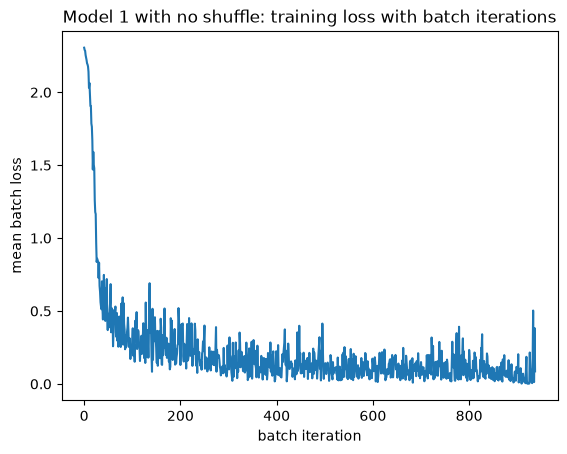

In [8]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots()
ax.plot(range(len(losses_1)), losses_1)
ax.set(xlabel = 'batch iteration', ylabel = 'mean batch loss',
       title = 'Model 1 with no shuffle: training loss with batch iterations' )
plt.show()


0.21039852394858996


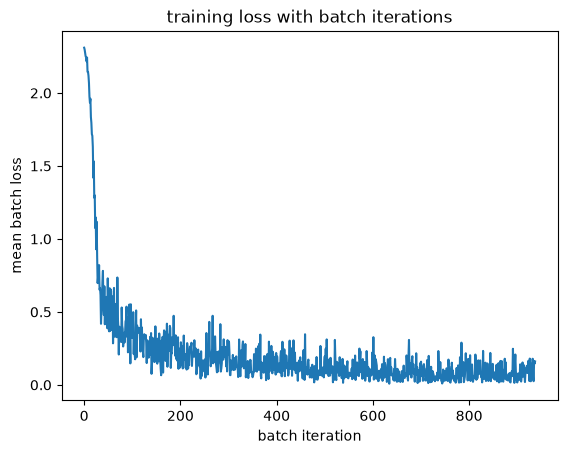

In [9]:
# set up
model2 = nn_model.NeuralNetwork()
model2.load_state_dict(torch.load('model_weights.pth', weights_only=True))
optimizer2 = torch.optim.Adam(model2.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss() #default reduction = 'mean'
# Create data loaders.
train_dataloader_2 = DataLoader(train_data, batch_size=64, shuffle=True)
losses_2 = []
total_loss_2 = 0
samples_seen_2 = 0

model2.train()
# training one epoch
for images, labels in iter(train_dataloader_2):
    batch_loss = update_one_batch(model2, optimizer2, loss_fn, images, labels)
    losses_2.append(batch_loss)
    actual_batch_size = len(labels)
    total_loss_2 += batch_loss * actual_batch_size
    samples_seen_2 += actual_batch_size

print(total_loss_2/samples_seen_2)

fig, ax = plt.subplots()
ax.plot(range(len(losses_2)), losses_2)
ax.set(xlabel = 'batch iteration', ylabel = 'mean batch loss',
       title = 'training loss with batch iterations' )
plt.show()


In [11]:
losses_1 == losses_2

False

os.makedirs('../data/train', exist_ok=True)
img1.save("../data/train/0_image_5.png")
img1.save('../data/train/0_image_5_default.jpg', quality=75)

In [67]:
from PIL import Image
read_jpg_1 = Image.open('../data/train/0_image_5.png')
read_jpg_1_default = Image.open('../data/train/0_image_5_default.jpg')
read_jpg_1_95 = Image.open('../data/train/0_image_5_95.jpg')

In [106]:
import PIL
from PIL import features

print("Pillow:", PIL.__version__)
print("JPEG codec:", features.version_codec("jpg"))
print("Image mode:", img.mode)

Pillow: 12.3.0
JPEG codec: 6.2
Image mode: L


In [ ]:
import importlib
from src import preprocessing

importlib.reload(preprocessing)

In [ ]:
from torch.utils.data import TensorDataset

# Isolate split randomness from model initialization and other notebook work.
split_generator = torch.Generator().manual_seed(34)

In [ ]:
# Download the dataset
data = datasets.MNIST(root='../data', train=True, download=True)


In [ ]:
training_set, validation_set = preprocessing.validation_split(
    data, train_ratio=0.8, generator=split_generator
)
training_set[0], len(training_set), len(validation_set)

In [ ]:
training_set[0][0]

In [ ]:
# MNIST stores raw images and labels as tensors. Select both with the
# same subset indices, then add the explicit channel dimension.
# This fast path uses raw storage, so it intentionally bypasses dataset transforms.
def prepare_mnist_subset(subset):
    indices = torch.tensor(subset.indices, dtype=torch.long)
    images = subset.dataset.data.index_select(0, indices).unsqueeze(1)
    labels = subset.dataset.targets.index_select(0, indices)
    return preprocessing.padding_image(images), labels

training_padded_tensor, train_labels = prepare_mnist_subset(training_set)

In [ ]:
train_std, train_u = torch.std_mean(training_padded_tensor)
train_u, train_std

In [ ]:
# Normalize whole batches; validation never contributes to these statistics.
train_tensor = preprocessing.normalize_image(
    training_padded_tensor, train_u, train_std
)
validation_padded_tensor, validation_labels = prepare_mnist_subset(validation_set)
validation_tensor = preprocessing.normalize_image(
    validation_padded_tensor, train_u, train_std
)

training_prepared = TensorDataset(train_tensor, train_labels)
validation_prepared = TensorDataset(validation_tensor, validation_labels)

# Release intermediate float tensors once the prepared datasets own the results.
del training_padded_tensor, validation_padded_tensor

In [ ]:
train_tensor.mean(), train_tensor.std(), train_tensor.shape

In [ ]:
validation_tensor.mean(), validation_tensor.std(), validation_tensor.shape